# Tutorial: a 2D axisymmetric coil, step by step

This notebook builds and runs a complete pyTEC3D analysis interactively: the case `docs/tutorials/data/coil_2D_avolt`. Two rings of
square cross-section sit one above the other, in 2D axisymmetry about the y axis:

* the **lower ring** is a *circuit-coupled conductor*, a massive conductor with a terminal: its current is not imposed
  point by point, it follows from the electric field; the ring is driven through its terminal (the voltage `V` across
  its circumference), first by its total current (100 A), then by a voltage (1 mV);
* the **upper ring** is a *solid conductor*, a passive closed ring: only eddy currents, induced by the changing flux,
  flow in it.

Along the way the notebook shows the objects of the package (`Solver`, `Model`, the mesh arrays, the model data, the
element library), the selections, the boundary conditions, the DOF couplings, the time steps and how to read and plot
the results. Each section links to the page of the user manual that describes the step in detail.

Run it from `docs/tutorials` with the `pytec3d` environment (`jupyter lab` or `jupyter notebook`; install
`ipykernel` in the environment if needed). It works on a copy of the case in a temporary folder, so the files of
`tests/` are not modified.

## 1. Setup

The case folder holds the mesh (`coil_2D_avolt.vtu`) and the model data (`model_data.json`). We copy them into a fresh
working directory: a run writes its log, the `output/` folder and the element matrices (`emat/`) in the working
directory.

In [1]:
import os, shutil, tempfile, json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import pytec3d
from pytec3d import Solver, selection, element_library
from pytec3d import mesh as meshes

CASE = Path("data/coil_2D_avolt").resolve()           # the test case of the repository
WORK = Path(tempfile.mkdtemp(prefix="pytec3d_tutorial_"))   # a scratch working directory
for name in ("coil_2D_avolt.vtu", "model_data.json"):
    shutil.copy(CASE / name, WORK / name)
os.chdir(WORK)

pytec3d.set_log_level("WARNING")   # keep the notebook readable: everything is in the job log anyway
print("pytec3d", pytec3d.__version__, "- working in a temporary folder:", WORK.name)

pytec3d 0.1.0 - working in a temporary folder: pytec3d_tutorial_7f1j_qf1


## 2. The solver and the model

A `Solver` is one analysis: it owns the **model** (mesh + model data), the **time step** settings, the **solver
settings** and the C++ solver session. `read_model()` reads the VTK grid, names the model after the file, adds the
arrays the element types need and clears the selection. (User manual: *The Analysis Workflow*, *The Mesh*.)

In [2]:
solver = Solver()
solver.read_model("coil_2D_avolt.vtu")
mesh = solver.model.mesh
print(solver.model)
print("log file:", Path(solver.log_file).name)

Model('coil_2D_avolt', 2521 points, 800 cells)
log file: coil_2D_avolt.log


Everything that varies over the model is an **array** of the grid: cell arrays (one value per cell) and point arrays
(one per node). The cell arrays `TYPE`, `MATERIAL` and `CONSTANT` say which rows of the model data each cell uses.

In [3]:
def arrays(data):
    return {data.GetArrayName(i): data.GetArray(i).GetNumberOfComponents() for i in range(data.GetNumberOfArrays())}

print("cell arrays :", arrays(mesh.GetCellData()))
print("point arrays:", arrays(mesh.GetPointData()))

for name in ("TYPE", "MATERIAL", "CONSTANT"):
    ids, counts = np.unique(meshes.array_values(mesh, name, "elem"), return_counts=True)
    print(f"{name:9s}", dict(zip(ids.astype(int).tolist(), counts.tolist())))

cell arrays : {'ansys_elem_num': 1, 'CONSTANT': 1, 'MATERIAL': 1, 'TYPE': 1, 'vtkOriginalCellIds': 1, 'Be': 3, 'He': 3, 'selection_cell': 1, 'cell_centroids': 3, 'COORDINATE_SYSTEM': 1, 'cell_volume': 1, 'B': 3, 'H': 3, 'Jt': 3, 'Js': 3}
point arrays: {'ansys_node_num': 1, 'BOUNDARY_NODES': 1, 'node_angles': 3, 'vtkOriginalPointIds': 1, 'origid': 1, 'Az': 1, 'E': 1, 'boundary_id_0': 1, 'MidsideNodes': 1, 'CP_0': 1, '_Az': 1, 'selection_point': 1, 'A': 3, '_A': 3, 'V': 1, '_V': 1, 'VOLT': 1, '_VOLT': 1, 'EMF': 1, '_EMF': 1, 'B': 3, 'H': 3, 'AMPS': 1, 'CURR': 1}
TYPE      {21: 768, 23: 16, 24: 16}
MATERIAL  {21: 768, 23: 16, 24: 16}
CONSTANT  {1: 800}


A quick look at the geometry: 2D axisymmetric means x is the radius r and y the axial coordinate z. The cells are
coloured by their `TYPE`: 21 air, 23 the active ring (bottom), 24 the passive ring (top).

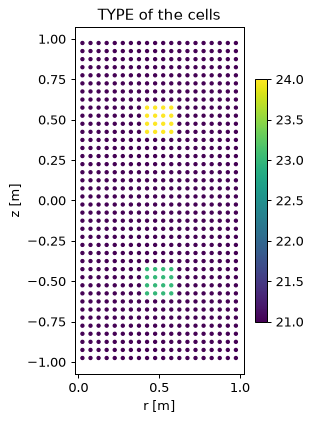

In [4]:
centroids = meshes.array_values(mesh, "cell_centroids", "elem")
types = meshes.array_values(mesh, "TYPE", "elem")
fig, ax = plt.subplots(figsize=(3.2, 5))
sc = ax.scatter(centroids[:, 0], centroids[:, 1], c=types, s=6, cmap="viridis")
ax.set_aspect("equal"); ax.set_xlabel("r [m]"); ax.set_ylabel("z [m]"); ax.set_title("TYPE of the cells")
fig.colorbar(sc, ax=ax, shrink=0.7)
plt.show()

## 3. The model data

The model data says what the ids mean: element type and domain of each `TYPE`, material properties of each
`MATERIAL`, real constants of each `CONSTANT`, DOF couplings, nonlinear laws, coordinate systems. It is read from a
JSON file (User manual: *The Model Data*).

In [5]:
solver.model.read_json("model_data.json")
data = solver.model.data
for type_id, row in data["element_types"].items():
    name = element_library.element_type_name(row["element_type"])
    domain = row["option1"] if isinstance(row["option1"], str) else element_library.domains()[row["option1"]]
    print(f"TYPE {type_id}: {name:11s} domain {domain:26s} FE order {row.get('option2', 1)}  axisymmetric {row.get('option3', 0)}")
print("materials    :", {k: {p: np.diag(v).tolist() for p, v in m.items()} for k, m in data["materials"].items()})
print("constants    :", data["constants"])
print("dof_couplings:", data["dof_couplings"])

TYPE 21: AV2D_nodal  domain NON_CONDUCTING             FE order 2  axisymmetric 1
TYPE 23: AV2D_nodal  domain CIRCUIT_COUPLED_CONDUCTOR  FE order 2  axisymmetric 1
TYPE 24: AV2D_nodal  domain SOLID_CONDUCTOR            FE order 2  axisymmetric 1
materials    : {'21': {'mur': [1.0, 1.0, 1.0], 'rho': [1.0, 1.0, 1.0]}, '23': {'mur': [1.0, 1.0, 1.0], 'rho': [1e-07, 1e-07, 1e-07]}, '24': {'mur': [1.0, 1.0, 1.0], 'rho': [1e-08, 1e-08, 1e-08]}}
constants    : {'1': {'thickness': 1.0}}
dof_couplings: {'1': ['V']}


* `TYPE 21` is air (`NON_CONDUCTING`): only the vector potential A_z, no current.
* `TYPE 23` is a `CIRCUIT_COUPLED_CONDUCTOR`: A_z plus the terminal voltage V; the material gives its resistivity.
* `TYPE 24` is a `SOLID_CONDUCTOR`: in 2D, a massive conductor without terminal, i.e. a closed (shorted) ring.
* `thickness = 1` makes the out-of-plane length 2 pi r: the full 360 degree ring.
* `dof_couplings["1"] = ["V"]`: the nodes with id 1 in the array `CP_0` will share one V.

The element library tells which arrays an element type reads and writes (User manual: *Element Library*):

In [6]:
print("element types:", element_library.element_type_names())
print("domains      :", element_library.domains())
for a in element_library.grid_arrays(["AV2D_nodal"]):
    print(f"  {a.name:6s} on {a.location:4s}, {a.components} component(s), default {a.fill}")

element types: ['AV2D_nodal', 'AV3D_nodal', 'AV3D_edge', 'AV2D_nodal_timint', 'AV3D_nodal_timint', 'AV3D_edge_timint']
domains      : ('NON_CONDUCTING', 'SOFT_MAGNETIC', 'HARD_MAGNETIC', 'STRANDED_CONDUCTOR', 'CIRCUIT_COUPLED_CONDUCTOR', 'SOLID_CONDUCTOR', 'STRANDED_COIL')
  A      on node, 3 component(s), default 0.0
  _A     on node, 3 component(s), default nan
  V      on node, 1 component(s), default 0.0
  _V     on node, 1 component(s), default nan
  VOLT   on node, 1 component(s), default 0.0
  _VOLT  on node, 1 component(s), default nan
  EMF    on node, 1 component(s), default 0.0
  _EMF   on node, 1 component(s), default nan
  B      on node, 3 component(s), default 0.0
  H      on node, 3 component(s), default 0.0
  B      on elem, 3 component(s), default 0.0
  H      on elem, 3 component(s), default 0.0
  Jt     on elem, 3 component(s), default 0.0
  Js     on elem, 3 component(s), default 0.0
  AMPS   on node, 1 component(s), default 0.0
  CURR   on node, 1 component(s), de

## 4. Boundary condition: A_z = 0 on the external boundary

Dirichlet values are written in the point array `_A` (NaN = free). In 2D the only DOF of A is its component 2 (A_z,
here A_theta). `select_all` + `nsel_ext` selects the nodes on the external boundary: the axis r = 0 (where A_theta
vanishes by symmetry) and the outer boundary (truncation of the open domain). (User manual: *Selections*, *Boundary
Conditions*.)

In [7]:
selection.select_all(mesh)
selection.nsel_ext(mesh)
selection.set_value_on_selection(mesh, "_A", 0.0, 2)
print("boundary nodes:", selection.selected_ids(mesh, "node").size)

boundary nodes: 240


## 5. The terminal of the circuit-coupled conductor: a DOF coupling

The V of a 2D circuit-coupled conductor is a single value for the whole cross-section. We select the cells of the ring,
then their nodes, and give them the CP id 1 in `CP_0`. The node with the **lowest id** of the group is the master: the
current load and the voltage of the terminal are set there. (User manual: *DOF Couplings*.)

In [8]:
selection.select(mesh, "MATERIAL", 23, location="elem")
selection.nsle(mesh)
selection.set_value_on_selection(mesh, "CP_0", 1)
master = int(selection.selected_ids(mesh, "node")[0])
print("nodes of the ring:", selection.selected_ids(mesh, "node").size, "- master node:", master)

nodes of the ring: 65 - master node: 1120


## 6. Load the model into the solver

`load_model_into_solver()` validates the model and creates the C++ session (mesh distribution, DOF numbering). From now
on the mesh and the model data are locked; array values (loads, Dirichlet values) can still change.

In [9]:
solver.load_model_into_solver()
print(solver)
try:
    solver.model.data = {}
except pytec3d.ModelLockedError as exc:
    print("locked:", str(exc)[:80], "...")

+--------------------------------------------------------------------------------------+
| Run                                                                                  |
+-------------------+------------------------------------------------------------------+
| Started           | 2026-10-20T15:03:57+02:00                                        |
| Command           | python tutorial_coil_2D.ipynb                                    |
| Working directory | /tmp/pytec3d_tutorial_7f1j_qf1                                   |
| Host / user       | workstation / user                                               |
| Platform          | Linux-5.14.0-687.58.1.el9_8.x86_64-x86_64-with-glibc2.34         |
| Python / numpy    | 3.12.15 / 2.5.4                                                  |
| pytec3d           | 0.1.0                                                            |
+-------------------+------------------------------------------------------------------+
| Input files (SHA-25

## 7. Time steps

`time_step["time"]` is the end time of each step; the first step starts at t = 0 from zero fields. We use backward
Euler (theta = 1): it damps the sudden changes of excitation of this example; a lower theta is only for smooth
excitations (see the remark on theta at the end of section 8). (User manual: *Time Steps and Analysis Types*.)

* Step 1: `AMPS = 100` on the master node: 100 A through the ring (current driven).
* Steps 2-4: `AMPS = 0` and `_V = 1e-3`: the ring is now driven by 1 mV across its circumference; its current
  follows from its resistance (about 8 micro-ohm) and from the induced voltage.

Fixing `_V` changes the set of constrained DOFs, so the solver refactorizes the matrix at step 2 and reuses it at
steps 3 and 4. The warning "No loads" is expected from step 2 on: the ring is driven by a Dirichlet value.

After each step we estimate the current of each ring from the element current density: the sum of `Jt * area` over
its cells (`cell_volume` holds the cell areas in 2D, component 2 of `Jt` is the toroidal one).

In [10]:
def ring_currents():
    jt = meshes.array_values(mesh, "Jt", "elem")[:, 2]
    area = meshes.array_values(mesh, "cell_volume", "elem")
    material = meshes.array_values(mesh, "MATERIAL", "elem")
    return [float(np.sum(jt[material == m] * area[material == m])) for m in (23, 24)]

solver.time_step["theta"] = 1.0
history = []
for i in (1, 2, 3, 4):
    solver.time_step["time"] = i * 1e-5
    selection.select(mesh, "ID", master)
    if i == 1:
        selection.set_value_on_selection(mesh, "AMPS", 100.0)
    else:
        selection.set_value_on_selection(mesh, "AMPS", 0.0)
        selection.set_value_on_selection(mesh, "_V", 1.0e-3)
    solver.solve()
    path = solver.write_output()
    step = solver.steps[-1]
    volt = float(meshes.array_values(mesh, "V", "node")[master])
    history.append((step["time"], volt, *ring_currents()))
    print(f"step {step['index']}: t = {step['time']:.1e} s, {step['convergence']}, true residual "
          f"{step['true_residual']:.1e}, matrix {'factorized' if step['report']['system_matrix_updated'] else 'reused'}"
          f" -> {Path(path).name}")

step 0: t = 1.0e-05 s, CONVERGED_ITS, true residual 4.8e-12, matrix factorized -> coil_2D_avolt_out_1.vtu
step 1: t = 2.0e-05 s, CONVERGED_ITS, true residual 1.7e-16, matrix factorized -> coil_2D_avolt_out_2.vtu
step 2: t = 3.0e-05 s, CONVERGED_ITS, true residual 1.9e-16, matrix reused -> coil_2D_avolt_out_3.vtu
step 3: t = 4.0e-05 s, CONVERGED_ITS, true residual 1.6e-16, matrix reused -> coil_2D_avolt_out_4.vtu


2026-10-20 15:03:57.719 [warning] No loads: the arrays Js, AMPS, CURR are all zero.
2026-10-20 15:03:57.751 [warning] No loads: the arrays Js, AMPS, CURR are all zero.
2026-10-20 15:03:57.775 [warning] No loads: the arrays Js, AMPS, CURR are all zero.


## 8. Results

The terminal voltage and the estimated ring currents of each step:

In [11]:
print("   time [s]       V [V]     I active [A]   I passive [A]")
for t, volt, i_active, i_passive in history:
    print(f"  {t:.1e}   {volt: .3e}   {i_active: .4e}    {i_passive: .4e}")

   time [s]       V [V]     I active [A]   I passive [A]
  1.0e-05    8.004e+00    1.0000e+02    -2.4807e+00
  2.0e-05    1.000e-03    9.9866e+01    -2.4775e+00
  3.0e-05    1.000e-03    9.9736e+01    -2.4744e+00
  4.0e-05    1.000e-03    9.9609e+01    -2.4713e+00


Two things to notice:

* At step 1 the estimated active current is the 100 A imposed: the element value of `Jt` is the mean over the cell
  area, so `Jt * area` summed over the ring is its current, even though the time step (10 us) is much shorter than the
  diffusion time of the ring and the current flows in a skin layer far thinner than the cells. The distribution
  inside a cell is not resolved: refine the mesh near the surface where local values matter.
* Theta: `Jt` uses the rate of A of the time scheme, the one of the equations, so its sums match the terminal current
  for any theta. The theta itself matters after the sudden changes of this example (100 A at t = 0, then the switch
  to voltage drive): with theta = 0.5 the active ring settles near 200 A instead of 100 A, because half of the rate
  of step 1 (the voltage that built up the 100 A) still acts at step 2. Use theta = 1 after sudden changes, a lower
  theta only for smooth excitations (User manual: *Time Steps and Analysis Types*).

The flux density on the nodes (last step), and the current density in the rings:

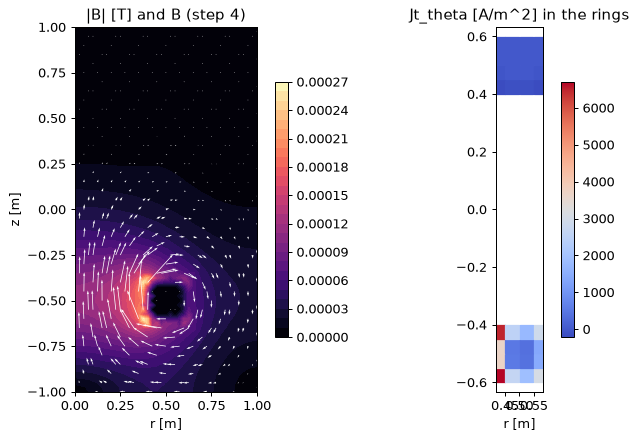

In [12]:
import matplotlib.tri as mtri
jt = meshes.array_values(mesh, "Jt", "elem")[:, 2]
xyz = meshes.points(mesh)
b = meshes.array_values(mesh, "B", "node")
tri = mtri.Triangulation(xyz[:, 0], xyz[:, 1])
fig, axes = plt.subplots(1, 2, figsize=(8, 5))
cs = axes[0].tricontourf(tri, np.linalg.norm(b, axis=1), levels=30, cmap="magma")
step = 6
axes[0].quiver(xyz[::step, 0], xyz[::step, 1], b[::step, 0], b[::step, 1], color="w", scale=None, width=0.004)
axes[0].set_aspect("equal"); axes[0].set_title("|B| [T] and B (step 4)"); axes[0].set_xlabel("r [m]"); axes[0].set_ylabel("z [m]")
fig.colorbar(cs, ax=axes[0], shrink=0.7)

cells = meshes.array_values(mesh, "TYPE", "elem") != 21
sc = axes[1].scatter(centroids[cells, 0], centroids[cells, 1], c=jt[cells], s=120, marker="s", cmap="coolwarm")
axes[1].set_aspect("equal"); axes[1].set_title("Jt_theta [A/m^2] in the rings"); axes[1].set_xlabel("r [m]")
fig.colorbar(sc, ax=axes[1], shrink=0.7)
plt.tight_layout(); plt.show()

### A 3D view with pyvista (optional)

[pyvista](https://docs.pyvista.org) wraps the VTK grid of the model directly (`pip install -e ".[notebooks]"`). Here the
2D solution is shown in its meridian plane, with the two rings revolved about the axis (y) for context.

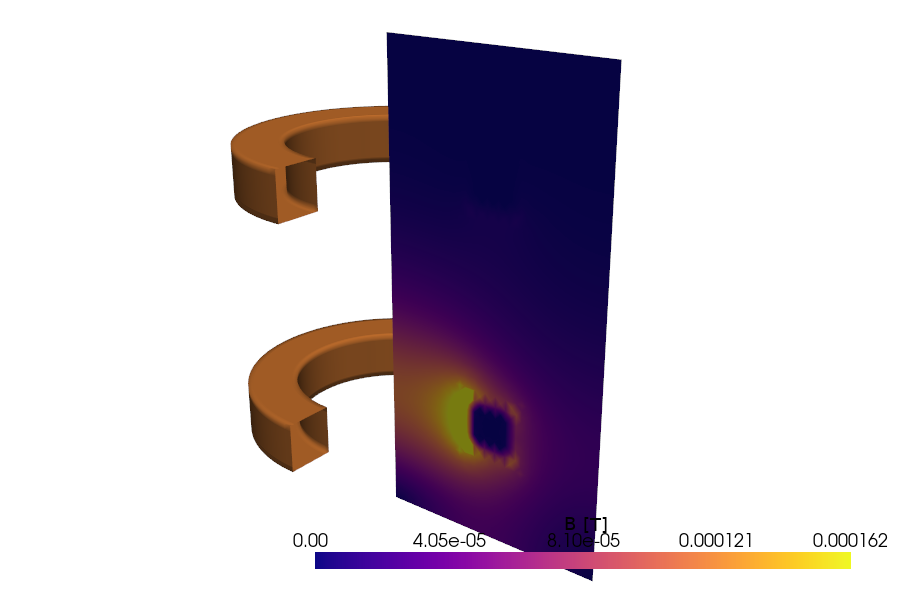

In [13]:
import pyvista as pv
pv.set_jupyter_backend("static")       # images in the notebook; "trame" gives interactive views

grid = pv.wrap(mesh).copy()            # a pyvista UnstructuredGrid of the model, with all its arrays
grid.point_data["|B|"] = np.linalg.norm(grid.point_data["B"], axis=1)
plane = grid.extract_surface(algorithm=None)
rings = (grid.threshold(value=(22, 30), scalars="TYPE").extract_surface(algorithm=None)
         .extract_feature_edges(boundary_edges=True, feature_edges=False, manifold_edges=False))
tori = rings.extrude_rotate(resolution=90, rotation_axis=(0, 1, 0), angle=270, capping=False)

pl = pv.Plotter(window_size=(900, 600))
pl.add_mesh(plane, scalars="|B|", cmap="plasma", clim=[0, np.percentile(plane["|B|"], 99)],
            scalar_bar_args={"title": "|B| [T]"})
pl.add_mesh(tori, color="#c87533", smooth_shading=True)
pl.camera_position = [(2.8, 1.6, 3.2), (0.3, 0.0, 0.0), (0, 1, 0)]
pl.show()

## 9. Files and reports

* `output/coil_2D_avolt_out_<n>.vtu`: the model after each step (open the series in ParaView);
* `coil_2D_avolt.log`: the job log, with the model tables, the constraints and the solver statistics of each step;
* `output/coil_2D_avolt_steps.csv`: one row per step, written when the solver is closed.

The full report of the C++ solver for a step is also available in Python:

In [14]:
report = solver.steps[-1]["report"]
print({k: report[k] for k in ("time", "dt", "transient", "system_matrix_updated", "linear_iterations", "true_residual", "total_dofs", "unconstrained_dofs")})
print("MUMPS:", {k: report["factorization"][k] for k in ("status", "memory_total_mb", "factor_entries")})

{'time': 4e-05, 'dt': 9.999999999999999e-06, 'transient': True, 'system_matrix_updated': False, 'linear_iterations': 1, 'true_residual': 1.6472137481657e-16, 'total_dofs': 2586, 'unconstrained_dofs': 2281}
MUMPS: {'status': 0, 'memory_total_mb': 2, 'factor_entries': 175295.0}


In [15]:
solver.close()          # run summary in the log, steps CSV
print(sorted(p.name for p in (WORK / "output").iterdir()))
print(open(WORK / "output" / "coil_2D_avolt_steps.csv").read())

+------------------------------------------------------------------------------------------------------------------+
| Run summary: coil_2D_avolt                                                                                       |
+------+------------+------------+------------+---------------+---------------+----------+-------------------------+
| Step | Time       | Newton its | Linear its | Convergence   | True residual | Wall (s) | Output                  |
+------+------------+------------+------------+---------------+---------------+----------+-------------------------+
|    0 | 1.0000e-05 | -          |          1 | CONVERGED_ITS |      4.81e-12 |     0.03 | coil_2D_avolt_out_1.vtu |
|    1 | 2.0000e-05 | -          |          1 | CONVERGED_ITS |      1.72e-16 |     0.02 | coil_2D_avolt_out_2.vtu |
|    2 | 3.0000e-05 | -          |          1 | CONVERGED_ITS |      1.93e-16 |     0.01 | coil_2D_avolt_out_3.vtu |
|    3 | 4.0000e-05 | -          |          1 | CONVERGED_ITS | 

## 10. Try it yourself

* Change the excitation: drive step 1 by a voltage instead (`_V` on the master node, `AMPS = 0`), or add steps to
  see the currents decay with `_V = 0` (a shorted ring, like the solid one).
* Run the same steps with theta = 0.5 and compare the ring currents (section 8); then run step 1 with theta = 1 and
  the next ones with theta = 0.5.
* Make the first step static (`time_step["transient_effects"] = False`): the passive ring then carries no current at
  step 1.
* Use the time-integrated formulation: set `"element_type": "AV2D_nodal_timint"` in every row of the model data
  (before loading). `_V` then fixes the time integral of the voltage.
* Add an iron yoke with a B-H curve, as in `tests/coil_2D_avolt_ferr` (User manual: *Nonlinear Materials*).
* Replace the driven ring by a stranded coil with its circuit equation, as in `tests/coil_2D_avoltemf`.

The commented macros of `tests/` (see *Examples*) show these variants and the 3D versions of the same model.